In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Optional, Tuple
from pathlib import Path
import os
from glob import glob

import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import sys
import h5py
from scipy import signal
# Add src to path for custom utilities
sys.path.insert(0, f'/home/obandohe/JIPSENSE/JIPSENSE')
from src.utils.seismic_io import load_traces_from_hdf5, print_hdf5_info
from src.utils.fk_spectrum_class import FKSpectrum
from src.utils.Preprocessing_SW import agc_gain, Array_to_ObsPy
import src.utils.wft as wft
from obspy.signal.tf_misfit import cwt
print("✓ All libraries imported successfully")
from obspy import Trace, Stream, UTCDateTime

✓ All libraries imported successfully


In [5]:
def getSpectrum(data_mod,fs,dx,fmin,fmax,vel_min,vel_max):
    ''' Function to compute the wavefield transform of a given data set
    Parameters:
    data_mod: data to be transformed
    fs: sampling frequency in Hz
    dx: receiver spacing in meters
    fmin: minimum frequency in Hz
    fmax: maximum frequency in Hz
    vel_min: minimum velocity in m/s
    vel_max: maximum velocity in m/s

    returns:
    power: power spectrum 
    power_norm: normalized power spectrum
    frequencies: frequencies
    velocities: velocities

    '''
    # receiver coordinates
    offsets = np.arange(data_mod.shape[1])*dx
    # velocity range
    velocities = np.linspace(vel_min,vel_max,250)
    # parameters for the wavefield transform
    settings = {'fmin':fmin,'fmax':fmax,'fdbf_weighting':'sqrt','fdbf_steering':'cylindrical'}
    # normalize data
    data_norm = data_mod/np.max(np.abs(data_mod),axis=0)
    # perform wavefield transform
    tmatrix = np.transpose(data_norm)
    frequencies, power = wft.phase_shift(tmatrix, offsets, fs, velocities, settings)
    # normalize power spectrum
    power_norm = np.abs(power)/np.max(np.abs(power),axis=0)

    return np.abs(power), power_norm, frequencies, velocities

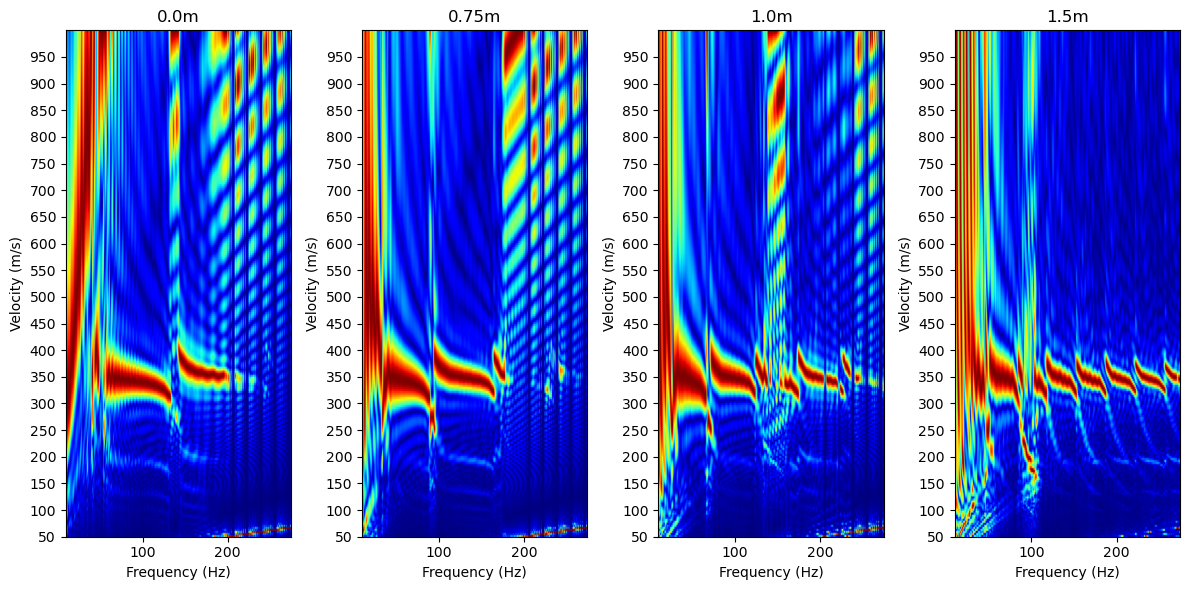

In [6]:
# read STATIONS

#models = ['simulation_sediment_on_top_0.5m', 'simulation_lateral_variation','simulation_inclined_layer']

#models = ['simulation_sediment_on_top_0.5m','simulation_coupling_sediment_on_top']


models = ['simulation_sediment_on_top_0.5m','simulation_sediment_on_top_0.75m', 'simulation_sediment_on_top_1.0m','simulation_sediment_on_top_1.5m']

fig,axs = plt.subplots(1, len(models), figsize=(12, 6))


for ii, model_name in enumerate(models):

    signal_type = 'PRE.semp'

    if signal_type=='PRE.semp':
        signal_suffix = 'pressure'
    elif signal_type=='FXX.semv':
        signal_suffix = 'VXX'
    elif signal_type=='FXZ.semv':
        signal_suffix = 'VXZ'
    else:
        raise ValueError(f"Unsupported signal type: {signal_type}")

    source_type = 'tr'  # or 'tr'

    # test saving and loading the h5 file
    filename = f"/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/hdf5_files_JAP/{model_name}_JAP_{signal_suffix}_{source_type}.h5"
    with h5py.File(filename, "r") as f:
        data_loaded = f["data"][:]
        fs_loaded = f["fs"][()]
        station_coords_loaded = f["receiver_coordinates"][:]
        params_loaded = f["params"][()].decode("utf-8")


    data_loaded = data_loaded[:550,:]

    # compute pvs

    power, power_norm, frequencies, velocities = getSpectrum(data_loaded, fs_loaded, station_coords_loaded[1,0]-station_coords_loaded[0,0], fmin=10.0, fmax=600.0, vel_min=50.0, vel_max=1000.0)

    # convert the loaded data to obspy obspy Trace objects


    traces = []
    for i in range(data_loaded.shape[1]):
        tr = Trace()
        tr.data = data_loaded[:, i]
        tr.stats.station = f"STA{i:03d}"
        tr.stats.network = "XX"
        tr.stats.channel = signal_suffix
        tr.stats.sampling_rate = fs_loaded
        tr.stats.starttime = UTCDateTime(0)
        traces.append(tr)

    st = Stream(traces=traces)

    # filter the stream with a bandpass filter
    st.filter("bandpass", freqmin=10.0, freqmax=600.0)

    # extract data from the obspy Stream object
    data_from_stream = np.array([tr.data for tr in st]).T



    axs[ii].imshow(power_norm, aspect='auto', cmap='jet',vmin=0, vmax=1, extent=[frequencies.min(), frequencies.max(), velocities.max(), velocities.min()])
    axs[ii].set_xlabel('Frequency (Hz)')
    axs[ii].set_ylabel('Velocity (m/s)')

    # define grid interval at every 20 m/s for velocity
    vel_grid_interval = 50
    vel_grid = np.arange(velocities.min(), velocities.max(), vel_grid_interval)
    axs[ii].set_yticks(vel_grid)


    if ii==0:
        name_ = '0.0m'
    else:
        name_ = model_name.split('_')[-1]


    axs[ii].set_title(name_)


    # invert y
    axs[ii].invert_yaxis()

plt.tight_layout()
plt.show()



In [7]:
frequencies

array([ 10. ,  10.5,  11. ,  11.5,  12. ,  12.5,  13. ,  13.5,  14. ,
        14.5,  15. ,  15.5,  16. ,  16.5,  17. ,  17.5,  18. ,  18.5,
        19. ,  19.5,  20. ,  20.5,  21. ,  21.5,  22. ,  22.5,  23. ,
        23.5,  24. ,  24.5,  25. ,  25.5,  26. ,  26.5,  27. ,  27.5,
        28. ,  28.5,  29. ,  29.5,  30. ,  30.5,  31. ,  31.5,  32. ,
        32.5,  33. ,  33.5,  34. ,  34.5,  35. ,  35.5,  36. ,  36.5,
        37. ,  37.5,  38. ,  38.5,  39. ,  39.5,  40. ,  40.5,  41. ,
        41.5,  42. ,  42.5,  43. ,  43.5,  44. ,  44.5,  45. ,  45.5,
        46. ,  46.5,  47. ,  47.5,  48. ,  48.5,  49. ,  49.5,  50. ,
        50.5,  51. ,  51.5,  52. ,  52.5,  53. ,  53.5,  54. ,  54.5,
        55. ,  55.5,  56. ,  56.5,  57. ,  57.5,  58. ,  58.5,  59. ,
        59.5,  60. ,  60.5,  61. ,  61.5,  62. ,  62.5,  63. ,  63.5,
        64. ,  64.5,  65. ,  65.5,  66. ,  66.5,  67. ,  67.5,  68. ,
        68.5,  69. ,  69.5,  70. ,  70.5,  71. ,  71.5,  72. ,  72.5,
        73. ,  73.5,